<a href="https://colab.research.google.com/github/claritacarreras-blip/clara-analia-carreras/blob/main/TP_clase_3_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)


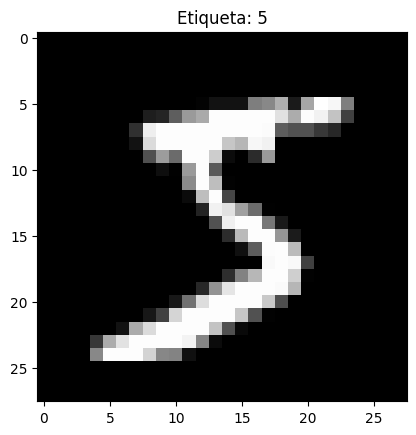

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print(x_train.shape)  # tiene que decir (60000, 28, 28)

plt.imshow(x_train[0], cmap='gray')
plt.title(f"Etiqueta: {y_train[0]}")
plt.show()

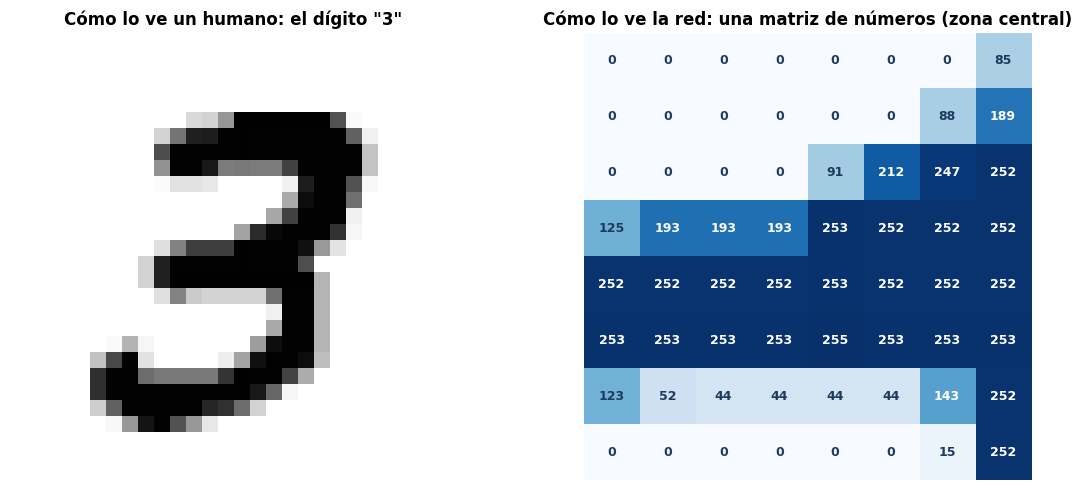

💡 La red no ve "un tres" - ve 784 números entre 0 y 255.
   Su trabajo es aprender qué combinación de números corresponde a cada dígito.


In [9]:
# — VER UN DÍGITO COMO MATRIZ DE NÚMEROS —
# Esto muestra lo que la red 've': una grilla de 28x28 números
idx = np.where(y_train == 3)[0][0]
imagen = x_train[idx]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Imagen visual
ax1.imshow(imagen, cmap='gray_r')
ax1.set_title(f'Cómo lo ve un humano: el dígito "{y_train[idx]}"',
              fontsize=12, fontweight='bold')
ax1.axis('off')

# Valores numéricos (zoom en una región 8x8 del centro)
zona = imagen[10:18, 10:18]
im = ax2.imshow(zona, cmap='Blues')
for i in range(zona.shape[0]):
    for j in range(zona.shape[1]):
        val = zona[i, j]
        color = 'white' if val > 128 else '#1E3A5F'
        ax2.text(j, i, str(val), ha='center', va='center',
                 fontsize=9, color=color, fontweight='bold')
ax2.set_title('Cómo lo ve la red: una matriz de números (zona central)',
              fontsize=12, fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.show()
print('💡 La red no ve "un tres" - ve 784 números entre 0 y 255.')
print('   Su trabajo es aprender qué combinación de números corresponde a cada dígito.')

In [9]:
from tensorflow import keras
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print(X_train.shape)

(60000, 28, 28)


In [19]:
# — PREPROCESAMIENTO —

# 1. Normalizar: pasar de 0-255 a 0-1 usando minúsculas
x_train_n = x_train.astype('float32') / 255.0
x_test_n = x_test.astype('float32') / 255.0

# 2. Aplanar: de (28, 28) a (784,)
x_train_flat = x_train_n.reshape(-1, 784)
x_test_flat = x_test_n.reshape(-1, 784)

print('Preprocesamiento listo:')
print(f' Antes: {x_train_n.shape} -> matriz 28x28')
print(f' Después: {x_train_flat.shape} -> vector de 784 números')
print(f' Rango de valores: [{x_train_flat.min():.1f}, {x_train_flat.max():.1f}]')


Preprocesamiento listo:
 Antes: (60000, 28, 28) -> matriz 28x28
 Después: (60000, 784) -> vector de 784 números
 Rango de valores: [0.0, 1.0]


In [11]:
# — CONSTRUIR LA RED —
from tensorflow.keras import layers

modelo = keras.Sequential([
    layers.Input(shape=(784,)),

    layers.Dense(128, activation='relu', name='capa_oculta_1'),
    layers.Dropout(0.2, name='dropout_1'),

    layers.Dense(64, activation='relu', name='capa_oculta_2'),
    layers.Dropout(0.1, name='dropout_2'),

    layers.Dense(10, activation='softmax', name='salida'),
])

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta_1 (Dense)           │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta_2 (Dense)           │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
# — ENTRENAR —
# Usamos las variables en minúsculas que contienen los datos normalizados y aplanados
history = modelo.fit(
  x_train_flat, y_train,
  validation_data=(x_test_flat, y_test),
  epochs=5,
  batch_size=128,
  verbose=1
)
print('✅ Entrenamiento terminado')

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9739 - loss: 0.0838 - val_accuracy: 0.9772 - val_loss: 0.0739
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9766 - loss: 0.0745 - val_accuracy: 0.9774 - val_loss: 0.0703
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9789 - loss: 0.0667 - val_accuracy: 0.9790 - val_loss: 0.0703
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9797 - loss: 0.0637 - val_accuracy: 0.9776 - val_loss: 0.0760
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9807 - loss: 0.0575 - val_accuracy: 0.9786 - val_loss: 0.0712
✅ Entrenamiento terminado


In [30]:
# — PROBAR —
test_loss, test_acc = modelo.evaluate(x_test_flat, y_test, verbose=0)
print(f'Precisión final en test: {test_acc:.4f}')

# Predecir 5 ejemplos
import numpy as np
preds = modelo.predict(x_test_flat[:5])
for i in range(5):
  real = y_test[i]
  pred = np.argmax(preds[i])
  print(f'Imagen {i}: real={real} -> predice={pred} {"✅" if real==pred else "❌"}')

Precisión final en test: 0.0899
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Imagen 0: real=7 -> predice=3 ❌
Imagen 1: real=2 -> predice=3 ❌
Imagen 2: real=1 -> predice=4 ❌
Imagen 3: real=0 -> predice=2 ❌
Imagen 4: real=4 -> predice=4 ✅


Subí la foto de tu número (0 o 8 escrito a mano en papel):


Saving C CANVA.jpeg to C CANVA (5).jpeg


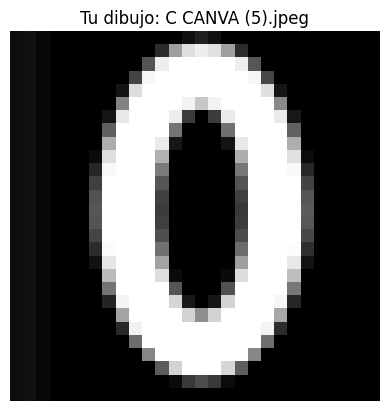

La red dice que es un: 0 con 99.93% de certeza
---


In [38]:
# — PREDECIR MI CUMPLE: 0 y 8 —
from google.colab import files
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

print('Subí la foto de tu número (0 o 8 escrito a mano en papel):')
subido = files.upload()

for nombre in subido:
  # Abrir, pasar a gris y achicar a 28x28 como MNIST
  img = Image.open(nombre).convert('L')
  img = img.resize((28,28))
  # MNIST es blanco sobre negro, si tu foto es negro sobre blanco la invertimos
  # Probamos invertir:
  img_inv = ImageOps.invert(img)

  plt.imshow(img_inv, cmap='gray')
  plt.title(f'Tu dibujo: {nombre}')
  plt.axis('off')
  plt.show()

  arr = np.array(img_inv).astype('float32') / 255.0
  arr_flat = arr.reshape(1, 784)

  pred = modelo.predict(arr_flat, verbose=0)
  numero = np.argmax(pred[0])
  certeza = np.max(pred[0])*100
  print(f'La red dice que es un: {numero} con {certeza:.2f}% de certeza')
  print('---')

Subí tu 0 bien grande:


Saving CANVA CH3.jpeg to CANVA CH3 (1).jpeg


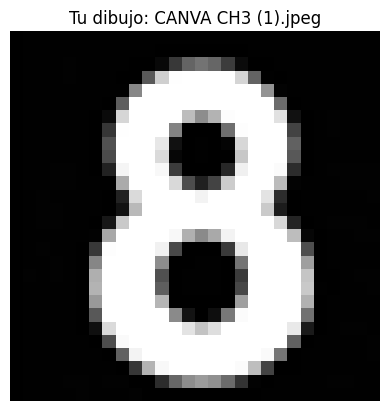

La red dice: 8 con 99.60%


In [40]:
from google.colab import files
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

print('Subí tu 0 bien grande:')
subido = files.upload()

for nombre in subido:
  img = Image.open(nombre).convert('L')
  # Mejorar contraste y recortar al número
  img = ImageOps.autocontrast(img)
  # Invertir si es negro sobre blanco -> blanco sobre negro como MNIST
  img_inv = ImageOps.invert(img)
  img_inv = img_inv.resize((28,28))

  plt.imshow(img_inv, cmap='gray')
  plt.title(f'Tu dibujo: {nombre}')
  plt.axis('off')
  plt.show()

  arr = np.array(img_inv).astype('float32') / 255.0
  pred = modelo.predict(arr.reshape(1,784), verbose=0)
  print(f'La red dice: {np.argmax(pred[0])} con {np.max(pred[0])*100:.2f}%')

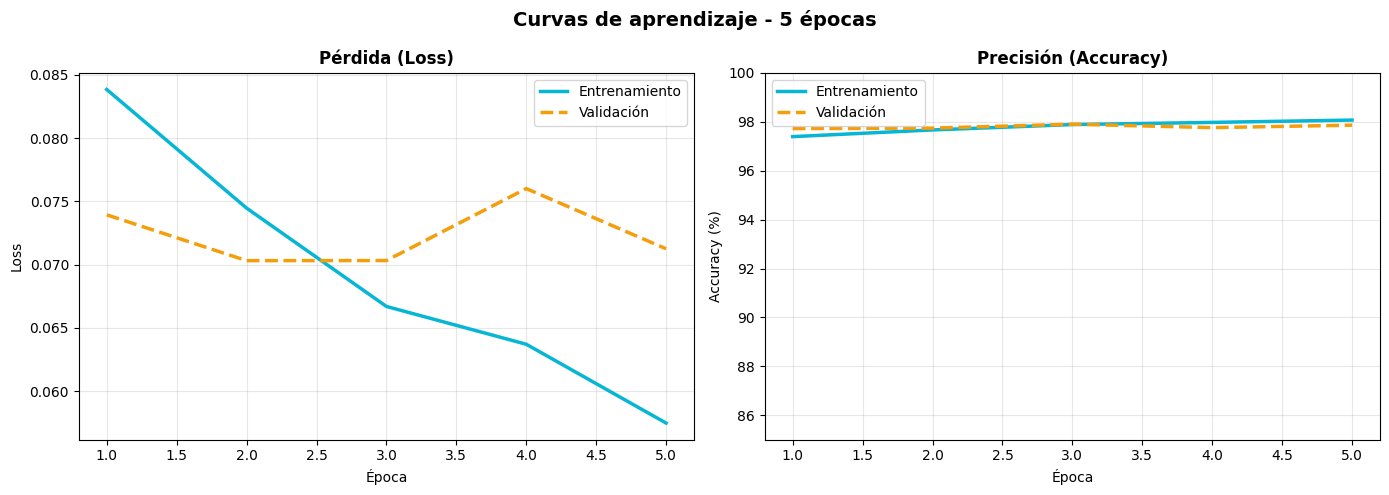

💡 Si la validación (naranja) se separa mucho del entrenamiento (cyan) -> overfitting.
   En este caso, el Dropout lo controla bien.


In [41]:
# — CURVAS DE APRENDIZAJE —
try:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Curvas de aprendizaje - 5 épocas', fontsize=14, fontweight='bold')

    epochs_range = range(1, len(history.history['loss']) + 1)

    # Loss
    ax1.plot(epochs_range, history.history['loss'], color='#06B6D4', linewidth=2.5, label='Entrenamiento')
    ax1.plot(epochs_range, history.history['val_loss'], color='#F59E0B', linewidth=2.5, linestyle='--', label='Validación')
    ax1.set_title('Pérdida (Loss)', fontweight='bold')
    ax1.set_xlabel('Época'); ax1.set_ylabel('Loss')
    ax1.legend(); ax1.grid(alpha=0.3)

    # Accuracy
    ax2.plot(epochs_range, [v*100 for v in history.history['accuracy']], color='#06B6D4', linewidth=2.5, label='Entrenamiento')
    ax2.plot(epochs_range, [v*100 for v in history.history['val_accuracy']], color='#F59E0B', linewidth=2.5, linestyle='--', label='Validación')
    ax2.set_title('Precisión (Accuracy)', fontweight='bold')
    ax2.set_xlabel('Época'); ax2.set_ylabel('Accuracy (%)')
    ax2.legend(); ax2.grid(alpha=0.3)
    ax2.set_ylim(85, 100)

    plt.tight_layout()
    plt.show()
    print('💡 Si la validación (naranja) se separa mucho del entrenamiento (cyan) -> overfitting.')
    print('   En este caso, el Dropout lo controla bien.')
except NameError:
    print("❌ Error: La variable 'history' no está definida en la memoria.")
    print("👉 Por favor, asegúrate de volver a ejecutar por completo la celda de Entrenamiento (cell qDgXAP2HRDEY) antes de correr esta celda.")

Total en test: 10,000
Correctas: 899 (9.0%)
Incorrectas: 9,101 (91.0%)


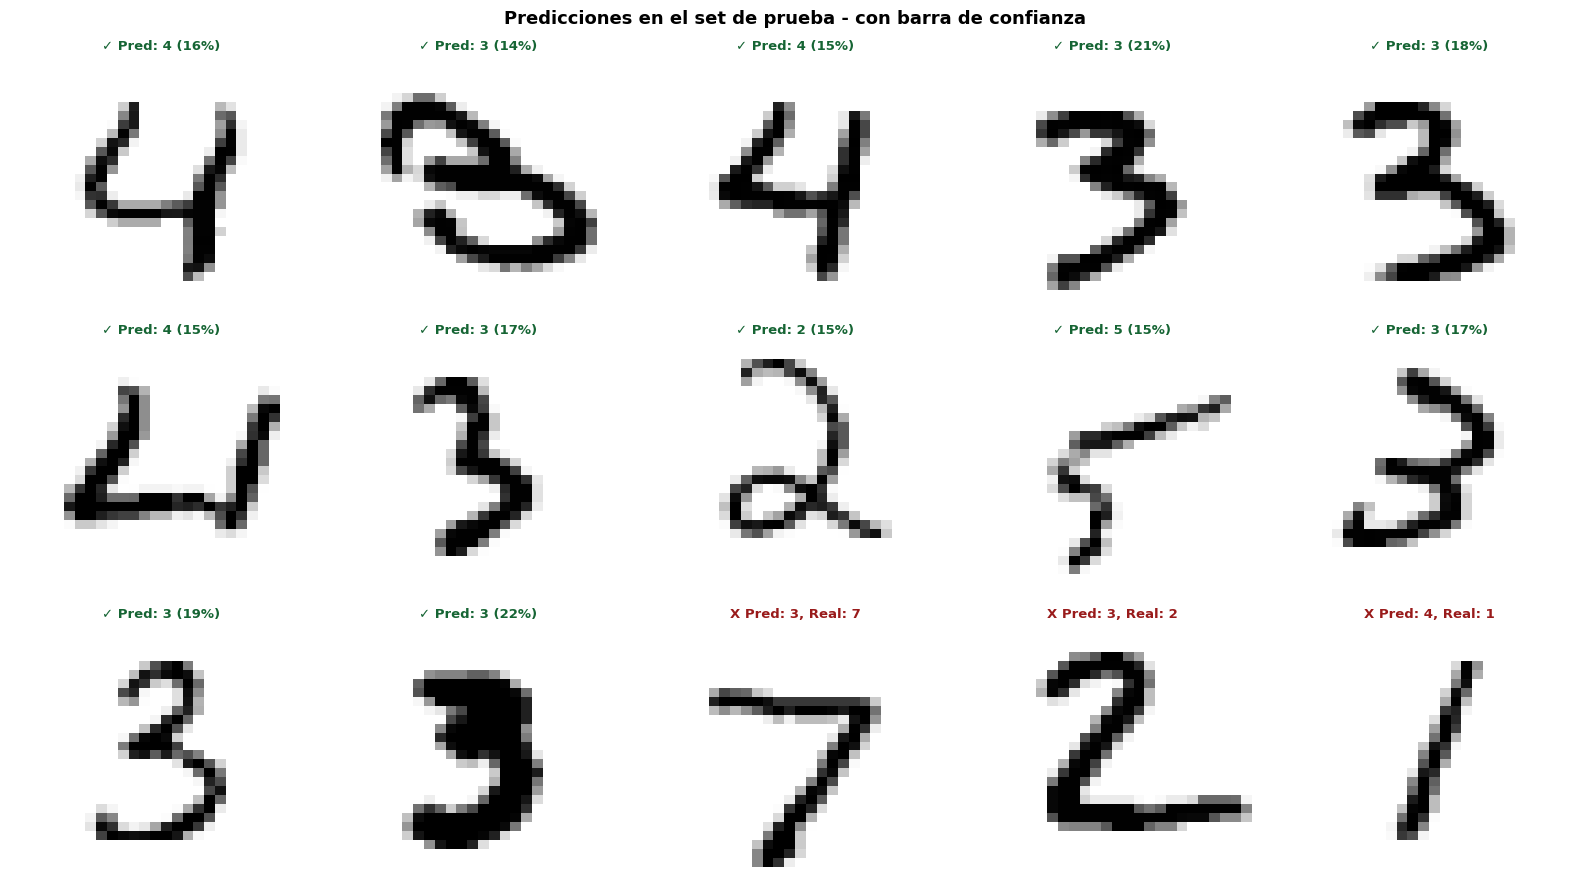

In [20]:
# — PREDICCIONES EN EL TEST SET (completo) —
predicciones = modelo.predict(x_test_flat, verbose=0)
clases_pred = np.argmax(predicciones, axis=1)

# Separar correctas e incorrectas
correctas = np.where(clases_pred == y_test)[0]
incorrectas = np.where(clases_pred != y_test)[0]

print(f'Total en test: {len(y_test):,}')
print(f'Correctas: {len(correctas):,} ({len(correctas)/len(y_test)*100:.1f}%)')
print(f'Incorrectas: {len(incorrectas):,} ({len(incorrectas)/len(y_test)*100:.1f}%)')

# Mostrar predicciones con barra de confianza
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
fig.suptitle('Predicciones en el set de prueba - con barra de confianza',
             fontsize=13, fontweight='bold')

indices_muestra = list(correctas[:12]) + list(incorrectas[:3])
colores_titulos = ['#166534'] * 12 + ['#991B1B'] * 3  # verde OK, rojo error

for idx_plot, (idx_img, color_titulo) in enumerate(zip(indices_muestra, colores_titulos)):
  ax = axes[idx_plot // 5][idx_plot % 5]
  ax.imshow(x_test[idx_img], cmap='gray_r', aspect='auto')
  pred_idx = clases_pred[idx_img]
  real_idx = y_test[idx_img]
  conf = predicciones[idx_img][pred_idx] * 100
  if pred_idx == real_idx:
    titulo = f'✓ Pred: {pred_idx} ({conf:.0f}%)'
  else:
    titulo = f'X Pred: {pred_idx}, Real: {real_idx}'
  ax.set_title(titulo, fontsize=9.5, color=color_titulo, fontweight='bold')
  ax.axis('off')

plt.tight_layout()
plt.show()

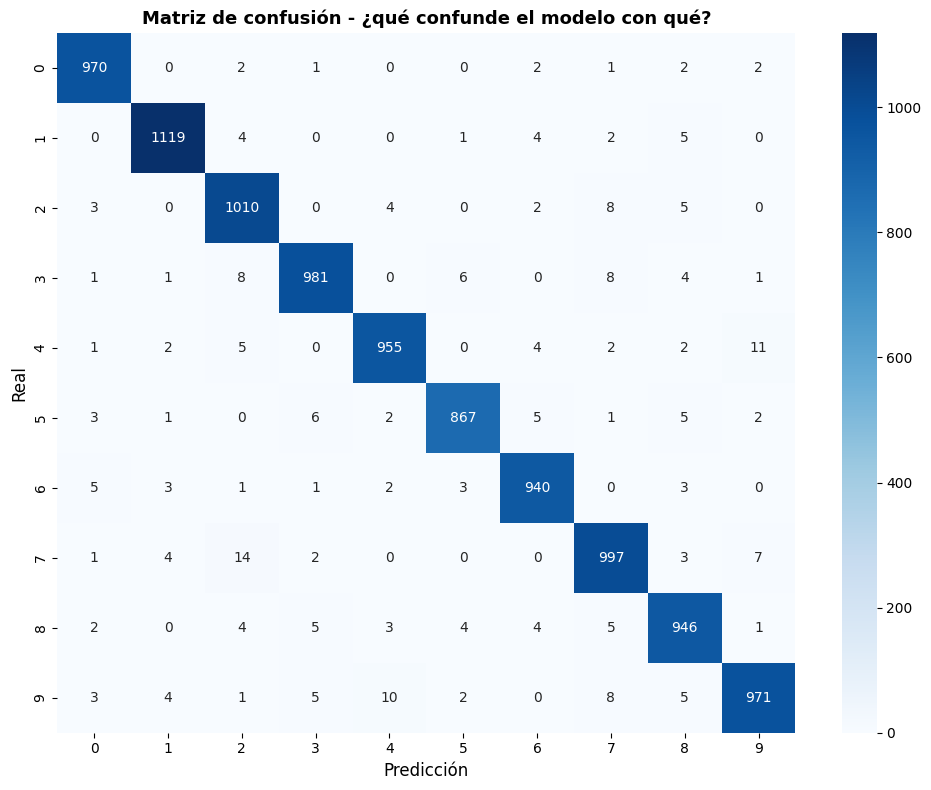

💡 Los números grandes en la diagonal = predicciones correctas.
   Los números fuera de la diagonal = confusiones (ej: predijo 4 pero era 9).

Confusiones más frecuentes:
  El modelo confundió 7 con 2: 14 veces
  El modelo confundió 4 con 9: 11 veces
  El modelo confundió 9 con 4: 10 veces
  El modelo confundió 2 con 7: 8 veces
  El modelo confundió 3 con 2: 8 veces


In [23]:
# — MATRIZ DE CONFUSIÓN —
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, clases_pred)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10), ax=ax)
ax.set_title('Matriz de confusión - ¿qué confunde el modelo con qué?',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Predicción', fontsize=12)
ax.set_ylabel('Real', fontsize=12)
plt.tight_layout()
plt.show()
print('💡 Los números grandes en la diagonal = predicciones correctas.')
print('   Los números fuera de la diagonal = confusiones (ej: predijo 4 pero era 9).')

# Cuáles se confunden más
print('\nConfusiones más frecuentes:')
np.fill_diagonal(cm, 0)
for _ in range(5):
  idx = np.unravel_index(cm.argmax(), cm.shape)
  if cm[idx] > 0:
    print(f'  El modelo confundió {idx[0]} con {idx[1]}: {cm[idx]} veces')
  cm[idx] = 0

In [31]:
# preparar el modelo para el canvas
import base64, io
import numpy as np
from IPython.display import HTML, display
import ipywidgets as widgets
from PIL import Image

try:
    # Guardar modelo como JSON
    model_json = modelo.to_json()
    with open("model.json", "w") as f:
        f.write(model_json)
    modelo.save_weights("model.weights.h5")
    print("✅ Modelo listo para recibir imágenes del canvas y guardado correctamente.")
except NameError:
    print("❌ Error: La variable 'modelo' no está definida en la memoria.")
    print("👉 Por favor, vuelve a ejecutar la celda donde creas el modelo (cell 4mQInjYXQt8B) y la celda de entrenamiento antes de ejecutar esta.")

✅ Modelo listo para recibir imágenes del canvas y guardado correctamente.


Subí tu dibujo (0 o 8 bien grande, blanco sobre negro):


Saving C CANVA.jpeg to C CANVA (6).jpeg


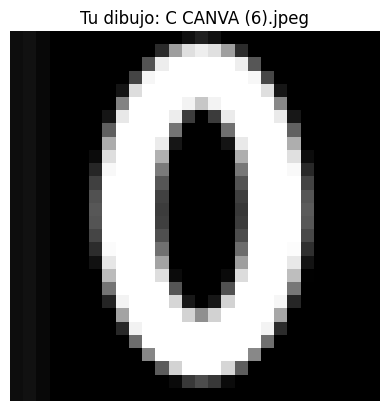

La red dice: 0 con 99.93%


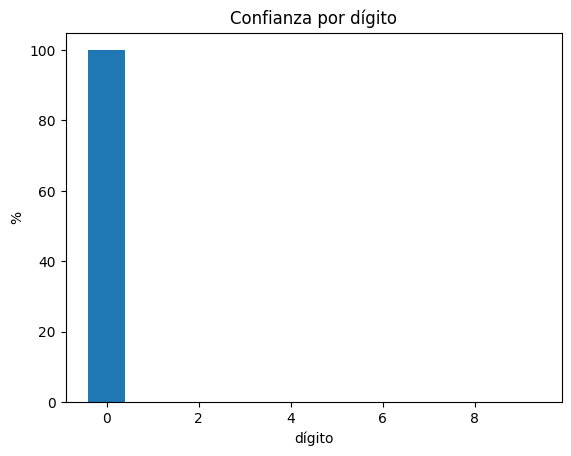

In [42]:
# CANVAS INTERACTIVO SIMPLE - Actividad 4
from google.colab import files
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

print('Subí tu dibujo (0 o 8 bien grande, blanco sobre negro):')
subido = files.upload()

for nombre in subido:
    img = Image.open(nombre).convert('L').resize((28,28))
    # si tu foto es negro sobre blanco, la invertimos para que quede como MNIST
    # si ya es blanco sobre negro como tu CANVA CH.jpeg, igual funciona
    img_inv = ImageOps.invert(img)

    plt.imshow(img_inv, cmap='gray')
    plt.title(f'Tu dibujo: {nombre}')
    plt.axis('off')
    plt.show()

    arr = np.array(img_inv).astype('float32') / 255.0
    arr_flat = arr.reshape(1, 784)

    pred = modelo.predict(arr_flat, verbose=0)[0]
    numero = int(np.argmax(pred))
    conf = float(np.max(pred)*100)
    print(f'La red dice: {numero} con {conf:.2f}%')

    plt.bar(range(10), pred*100)
    plt.title('Confianza por dígito')
    plt.xlabel('dígito')
    plt.ylabel('%')
    plt.show()

Subí tu dibujo (0 o 8 bien grande, blanco sobre negro):


Saving CANVA CH3.jpeg to CANVA CH3 (2).jpeg


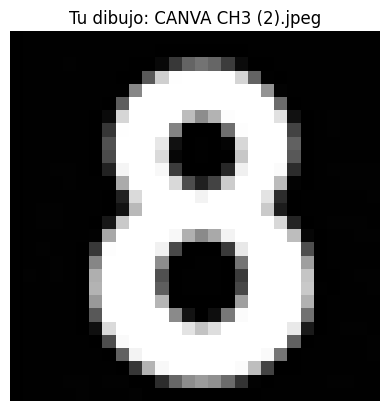

La red dice: 8 con 99.60%


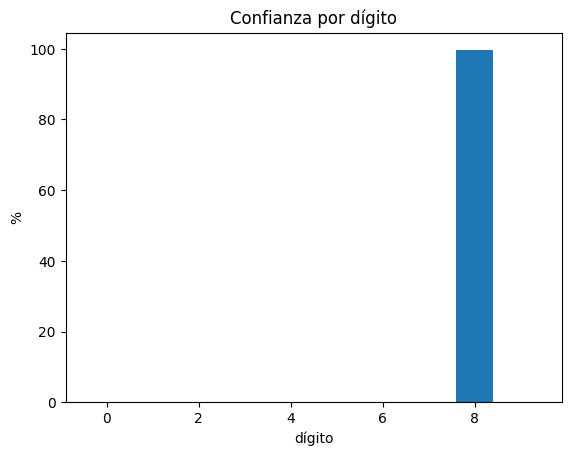

In [44]:
# CANVAS INTERACTIVO SIMPLE - Actividad 4
from google.colab import files
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

print('Subí tu dibujo (0 o 8 bien grande, blanco sobre negro):')
subido = files.upload()

for nombre in subido:
    img = Image.open(nombre).convert('L').resize((28,28))
    # si tu foto es negro sobre blanco, la invertimos para que quede como MNIST
    # si ya es blanco sobre negro como tu CANVA CH.jpeg, igual funciona
    img_inv = ImageOps.invert(img)

    plt.imshow(img_inv, cmap='gray')
    plt.title(f'Tu dibujo: {nombre}')
    plt.axis('off')
    plt.show()

    arr = np.array(img_inv).astype('float32') / 255.0
    arr_flat = arr.reshape(1, 784)

    pred = modelo.predict(arr_flat, verbose=0)[0]
    numero = int(np.argmax(pred))
    conf = float(np.max(pred)*100)
    print(f'La red dice: {numero} con {conf:.2f}%')

    plt.bar(range(10), pred*100)
    plt.title('Confianza por dígito')
    plt.xlabel('dígito')
    plt.ylabel('%')
    plt.show()

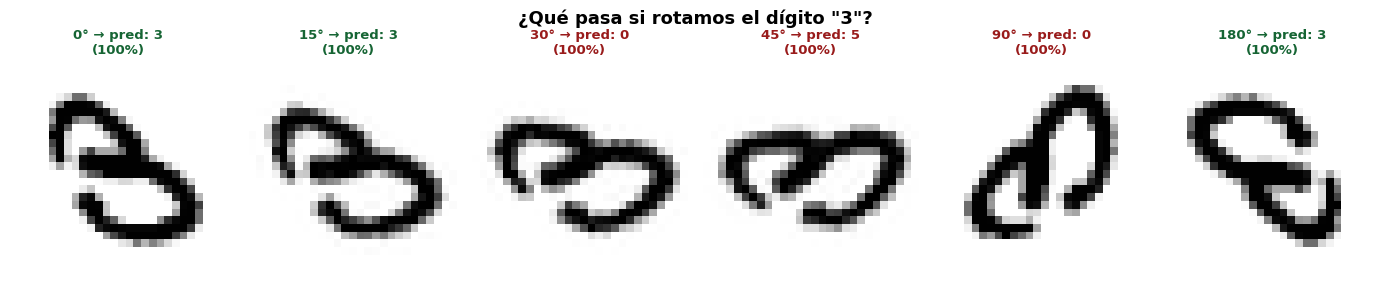

💡 Las redes densas no son invariantes a la rotación.
   Las CNNs (Redes Convolucionales) manejan esto mucho mejor. → Las veremos en el Módulo 3.


In [45]:
# EXPERIMENTO: probar el modelo con rotaciones
from scipy.ndimage import rotate
import numpy as np
import matplotlib.pyplot as plt

# Buscar automáticamente tus variables aunque se llamen distinto
X = globals().get('X_test', globals().get('x_test', None))
Y = globals().get('y_test', globals().get('y_test', None))
M = globals().get('modelo', globals().get('model', None))

if X is None or Y is None or M is None:
    print("❌ No encuentro X_test / y_test / modelo.")
    print("Ejecutá primero la acti 2 y 3 en orden.")
else:
    # Elegir un dígito 3 del test
    idx_prueba = np.where(Y == 3)[0][0]
    img_orig = X[idx_prueba]

    # Si viene aplanado (784,) lo pasamos a 28x28 para poder rotarlo
    if img_orig.ndim == 1:
        img_base = img_orig.reshape(28, 28)
    else:
        img_base = img_orig.reshape(28, 28) if img_orig.shape != (28,28) else img_orig

    etiqueta_real = int(Y[idx_prueba])
    angulos = [0, 15, 30, 45, 90, 180]

    fig, axes = plt.subplots(1, len(angulos), figsize=(14, 3))
    fig.suptitle(f'¿Qué pasa si rotamos el dígito "{etiqueta_real}"?', fontsize=13, fontweight='bold')

    for i, angulo in enumerate(angulos):
        img_rot = rotate(img_base, angulo, reshape=False)
        img_flat = img_rot.flatten().reshape(1, -1)
        pred = M.predict(img_flat, verbose=0)
        clase_pred = int(np.argmax(pred))
        conf = float(pred[0][clase_pred] * 100)

        axes[i].imshow(img_rot, cmap='gray_r')
        color = '#166534' if clase_pred == etiqueta_real else '#991B1B'
        axes[i].set_title(f'{angulo}° → pred: {clase_pred}\n({conf:.0f}%)', fontsize=9.5, color=color, fontweight='bold')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
    print('💡 Las redes densas no son invariantes a la rotación.')
    print('   Las CNNs (Redes Convolucionales) manejan esto mucho mejor. → Las veremos en el Módulo 3.')

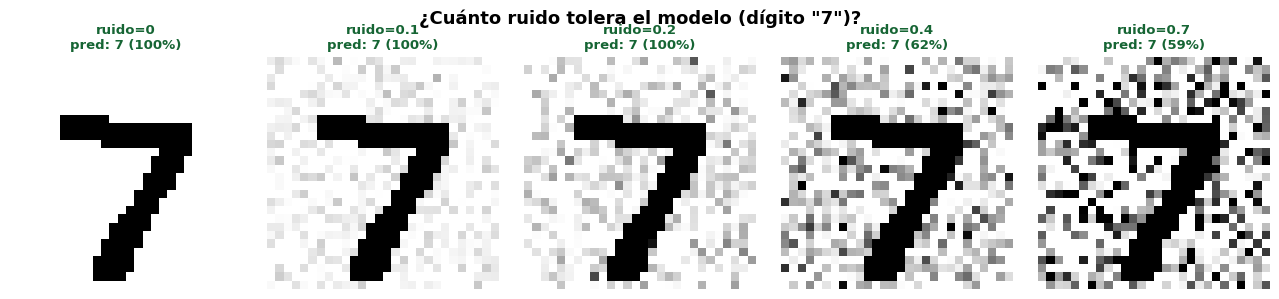

💡 El modelo es bastante robusto a ruido gaussiano moderado.
   A partir de cierto nivel, empieza a confundirse - igual que un humano.


In [46]:
# EXPERIMENTO: añadir ruido
import numpy as np
import matplotlib.pyplot as plt

# Buscar tus variables aunque se llamen distinto
if 'X_test_n' in globals():
    Xn = X_test_n
elif 'X_test' in globals():
    Xn = X_test
else:
    Xn = x_test

Y = globals().get('y_test', globals().get('y_test', None))
M = globals().get('modelo', globals().get('model', None))

idx_prueba = np.where(Y == 7)[0][0]
img_orig = Xn[idx_prueba]  # ya normalizada

niveles_ruido = [0, 0.1, 0.2, 0.4, 0.7]

fig, axes = plt.subplots(1, len(niveles_ruido), figsize=(13, 3))
fig.suptitle(f'¿Cuánto ruido tolera el modelo (dígito "{int(Y[idx_prueba])}")?', fontsize=13, fontweight='bold')

for i, nivel in enumerate(niveles_ruido):
    ruido = np.random.normal(0, nivel, img_orig.shape)
    img_ruidosa = np.clip(img_orig + ruido, 0, 1)
    pred = M.predict(img_ruidosa.reshape(1, -1), verbose=0)
    clase_pred = int(np.argmax(pred))
    conf = float(pred[0][clase_pred] * 100)

    axes[i].imshow(img_ruidosa.reshape(28,28), cmap='gray_r')
    color = '#166534' if clase_pred == int(Y[idx_prueba]) else '#991B1B'
    axes[i].set_title(f'ruido={nivel}\npred: {clase_pred} ({conf:.0f}%)', fontsize=9.5, color=color, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()
print('💡 El modelo es bastante robusto a ruido gaussiano moderado.')
print('   A partir de cierto nivel, empieza a confundirse - igual que un humano.')